# Kết quả cuối: validation vs test
Mọi lựa chọn (siêu tham số, mô hình, q*, chính sách theo nhóm) đã chốt bằng validation (`results/hparams.json`, `q_star_val.csv`, `policy_table_val.csv`); test chỉ dùng để đánh giá một lần.

In [1]:
import sys
from pathlib import Path
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
pd.set_option('display.width', 200)
order = ['WindowAverage','SeasonalNaive','CrostonSBA','TSB','LGBM-Q','LGBM-PoisNB','MLP-NB']
colors = {'WindowAverage':'#7f7f7f','SeasonalNaive':'#8c564b','CrostonSBA':'#bcbd22','TSB':'#2ca02c','LGBM-Q':'#1f77b4','LGBM-PoisNB':'#17becf','MLP-NB':'#d62728'}
val = pd.read_csv(ROOT/'results/forecast_eval_val_all.csv'); test = pd.read_csv(ROOT/'results/forecast_eval_test_all.csv')
qs = pd.read_csv(ROOT/'results/q_star_val.csv'); pol = pd.read_csv(ROOT/'results/policy_table_val.csv')
cmp_ = pd.read_csv(ROOT/'results/policy_eval_val_test.csv'); tr = pd.read_csv(ROOT/'results/test_qstar_transfer.csv')
print('Đã nạp kết quả val/test')

Đã nạp kết quả val/test


## 1. Chỉ số dự báo (H=3, tổng thể)

In [2]:
def tab(d, metric, H=3):
    return d[(d.H==H)&(d.group_type=='overall')&(d.metric==metric)].set_index('model').value.reindex(order)
t1 = pd.DataFrame({f'{m}_{s}': tab(d, m) for m in ['pinball_avg','wape','mase'] for s, d in [('val', val), ('test', test)]})
t1

,pinball_avg_val,pinball_avg_test,wape_val,wape_test,mase_val,mase_test
model,,,,,,
WindowAverage,1.075702,1.131586,0.412866,0.398724,0.812483,0.847428
SeasonalNaive,1.400214,1.411165,0.474148,0.439947,0.964484,0.988151
CrostonSBA,1.253938,1.265923,0.494778,0.448430,0.950220,0.917432
TSB,1.039800,1.079927,0.405767,0.389782,0.800872,0.828677
LGBM-Q,0.910854,0.935434,0.369665,0.350768,0.767183,0.787038
LGBM-PoisNB,0.930183,0.948748,0.369665,0.350768,0.767183,0.787038
MLP-NB,0.902532,0.947706,0.370057,0.351220,0.759731,0.783903


In [3]:
cov = lambda d, q: d[(d.H==3)&(d.group_type=='overall')&(d.metric=='coverage')&(np.isclose(d.q, q))].set_index('model').value.reindex(order)
pd.DataFrame({f'cov_q{q}_{s}': cov(d, q) for q in (0.5, 0.9, 0.99) for s, d in [('val', val), ('test', test)]})

,cov_q0.5_val,cov_q0.5_test,cov_q0.9_val,cov_q0.9_test,cov_q0.99_val,cov_q0.99_test
model,,,,,,
WindowAverage,0.584961,0.569399,0.889709,0.890597,0.967801,0.968829
SeasonalNaive,0.576502,0.551827,0.804328,0.797411,0.884428,0.880456
CrostonSBA,0.544490,0.523554,0.870736,0.873820,0.967053,0.966539
TSB,0.592485,0.580148,0.890457,0.896345,0.971166,0.974110
LGBM-Q,0.541172,0.512711,0.906346,0.902654,0.988083,0.987382
LGBM-PoisNB,0.598934,0.589261,0.912375,0.915646,0.981961,0.984157
MLP-NB,0.619778,0.600430,0.913497,0.910506,0.987382,0.983363


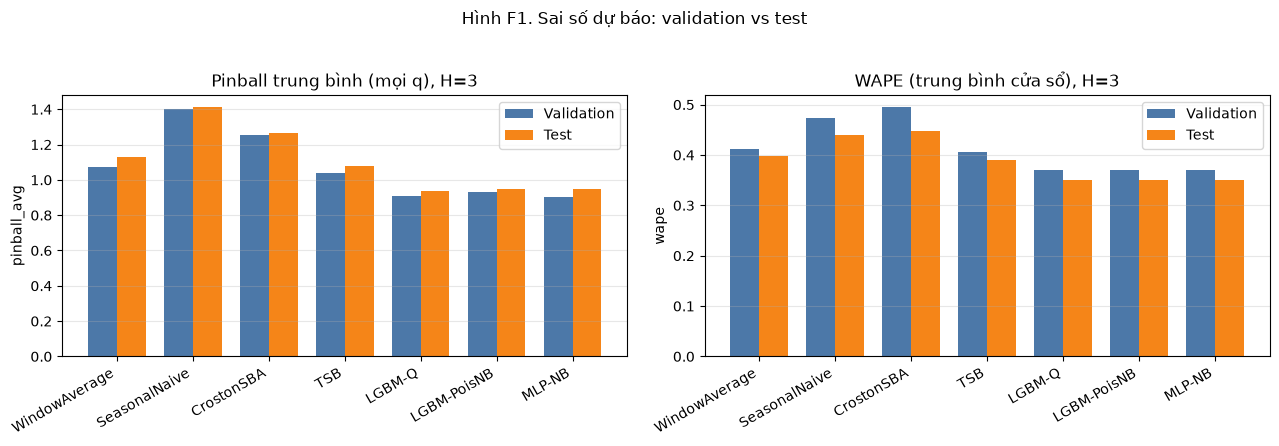

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(order)); w = 0.38
for a, metric, title in zip(ax, ['pinball_avg', 'wape'], ['Pinball trung bình (mọi q), H=3', 'WAPE (trung bình cửa sổ), H=3']):
    a.bar(x - w/2, tab(val, metric).values, w, label='Validation', color='#4c78a8')
    a.bar(x + w/2, tab(test, metric).values, w, label='Test', color='#f58518')
    a.set_xticks(x, order, rotation=30, ha='right'); a.set_title(title); a.set_ylabel(metric); a.legend(); a.grid(alpha=.3, axis='y')
fig.suptitle('Hình F1. Sai số dự báo: validation vs test')
fig.tight_layout(rect=[0,0,1,0.95]); fig.savefig(ROOT/'results/figures/final_val_vs_test_forecast.png', dpi=160); plt.show()

## 2. Chính sách q* chốt từ val, áp dụng trên test (cost_ratio=10)

In [5]:
t = tr[(tr.cost_ratio==10)].pivot(index='model', columns='L', values=['q_star_val','cost_val','cost_test','fill_val','fill_test','cost_point_test','gain_vs_point_val','gain_vs_point_test']).reindex(order)
t.round(4)

q_star_val       cost_val           cost_test           fill_val         fill_test         cost_point_test           gain_vs_point_val         gain_vs_point_test        
L                      2    3         2         3         2         3        2       3         2       3               2         3                 2       3                  2       3
model                                                                                                                                                                                  
WindowAverage        0.8  0.7  271.4933  289.8676  283.2892  306.9745   0.8740  0.8408    0.8683  0.8294        306.8226  317.4459           -0.0674 -0.0336            -0.0767 -0.0330
SeasonalNaive        0.7  0.6  305.1470  313.9903  308.2199  320.0680   0.8347  0.8061    0.8377  0.8052        320.7995  323.4046           -0.0207 -0.0065            -0.0392 -0.0103
CrostonSBA           0.8  0.7  301.1944  326.9465  304.2625  333.4617   0.8484  0.8069    0.8476  0.8014        335.2916  348.8007           -0.0759 -0.0335            -0.0925 -0.0440
TSB                  0.8  0.7  269.3244  288.6549  277.9247  301.4374   0.8791  0.8473    0.8799  0.8430        301.0486  312.3439           -0.0729 -0.0354            -0.0768 -0.0349
LGBM-Q               0.7  0.7  255.8554  274.3378  261.4253  279.8408   0.8785  0.8806    0.8744  0.8776        283.9842  294.0911           -0.0733 -0.0439            -0.0794 -0.0485
LGBM-PoisNB          0.8  0.7  256.4374  274.4982  259.9672  279.8323   0.9002  0.8632    0.9024  0.8648        283.9842  294.0911           -0.0712 -0.0434            -0.0846 -0.0485
MLP-NB               0.8  0.7  252.4508  270.0267  258.5030  278.5772   0.9062  0.8695    0.9034  0.8633        275.8068  290.9210           -0.0546 -0.0328            -0.0627 -0.0424

In [6]:
g = tr[tr.L==2].pivot(index='model', columns='cost_ratio', values='gain_vs_point_test').reindex(order)
print('Thay đổi chi phí TEST của q*(val) so với chính sách điểm (âm = rẻ hơn), L=2'); g.round(4)

Thay đổi chi phí TEST của q*(val) so với chính sách điểm (âm = rẻ hơn), L=2


cost_ratio,1.0,2.0,5.0,10.0,20.0,50.0
model,,,,,,
WindowAverage,-0.1091,-0.0688,0.0004,-0.0767,-0.2740,-0.5390
SeasonalNaive,-0.0723,-0.0530,-0.0138,-0.0392,-0.1906,-0.4419
CrostonSBA,-0.1188,-0.0726,-0.0002,-0.0925,-0.2926,-0.5614
TSB,-0.1106,-0.0732,-0.0041,-0.0768,-0.2712,-0.5440
LGBM-Q,-0.0569,-0.0410,-0.0079,-0.0794,-0.2726,-0.5507
LGBM-PoisNB,-0.1148,-0.0767,-0.0082,-0.0846,-0.2766,-0.5474
MLP-NB,-0.1052,-0.0749,-0.0098,-0.0627,-0.2352,-0.5054


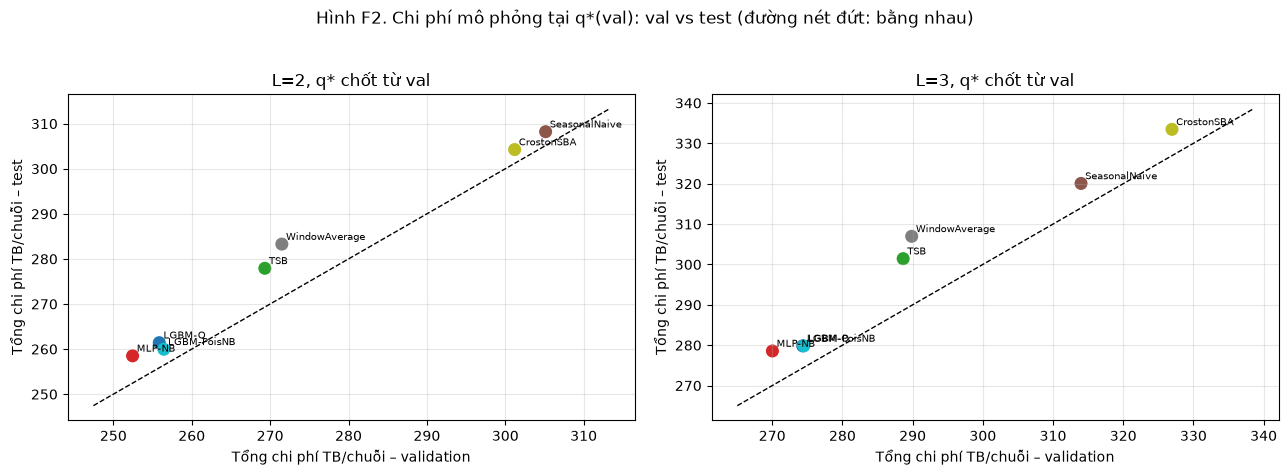

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax_, L in zip(axes, (2, 3)):
    s = tr[(tr.L==L)&(tr.cost_ratio==10)].set_index('model').reindex(order)
    ax_.scatter(s.cost_val, s.cost_test, c=[colors[m] for m in order], s=70)
    for m in order: ax_.annotate(m, (s.loc[m,'cost_val'], s.loc[m,'cost_test']), fontsize=7, xytext=(3,3), textcoords='offset points')
    lim = [min(s.cost_val.min(), s.cost_test.min())-5, max(s.cost_val.max(), s.cost_test.max())+5]
    ax_.plot(lim, lim, 'k--', lw=1); ax_.set(title=f'L={L}, q* chốt từ val', xlabel='Tổng chi phí TB/chuỗi – validation', ylabel='Tổng chi phí TB/chuỗi – test'); ax_.grid(alpha=.3)
fig.suptitle('Hình F2. Chi phí mô phỏng tại q*(val): val vs test (đường nét đứt: bằng nhau)')
fig.tight_layout(rect=[0,0,1,0.95]); fig.savefig(ROOT/'results/figures/final_cost_val_vs_test.png', dpi=160); plt.show()

## 3. Chính sách theo nhóm vs toàn cục vs điểm (cost_ratio=10)

In [8]:
o = cmp_[(cmp_.group_type=='overall')][['L','policy','split','fill_rate','stockout_days','avg_inventory','holding_cost','stockout_cost','total_cost']]
o.round(4)

,L,policy,split,fill_rate,stockout_days,avg_inventory,holding_cost,stockout_cost,total_cost
0,2,A_theo_nhom,val,0.8963,2.7120,6.2212,174.1932,77.6549,251.8481
17,2,"B_toan_cuc (MLP-NB, q=0.8)",val,0.9062,2.5152,6.5066,182.1835,70.2673,252.4508
34,2,C_diem (MLP-NB),val,0.8240,4.5176,4.8282,135.1896,131.8348,267.0243
51,2,A_theo_nhom,test,0.8918,2.7679,6.2146,174.0097,86.8044,260.8141
68,2,"B_toan_cuc (MLP-NB, q=0.8)",test,0.9034,2.5358,6.4662,181.0547,77.4484,258.5030
85,2,C_diem (MLP-NB),test,0.8210,4.6209,4.7235,132.2588,143.5480,275.8068
102,3,A_theo_nhom,val,0.8716,3.2406,6.1902,173.3256,96.1725,269.4982
119,3,"B_toan_cuc (MLP-NB, q=0.7)",val,0.8695,3.4241,6.1531,172.2868,97.7400,270.0267
136,3,C_diem (MLP-NB),val,0.8276,4.2661,5.3586,150.0413,129.1373,279.1786
153,3,A_theo_nhom,test,0.8640,3.2637,6.1211,171.3900,109.0765,280.4666


In [9]:
s = cmp_[(cmp_.group_type=='speed')&(cmp_.L==2)].pivot_table(index=['group','policy'], columns='split', values=['fill_rate','total_cost'])
s.round(4)

fill_rate         total_cost          
split                                  test     val       test       val
group  policy                                                           
fast   A_theo_nhom                   0.9032  0.9118   455.5706  437.4417
       B_toan_cuc (MLP-NB, q=0.8)    0.9169  0.9236   450.3252  438.7822
       C_diem (MLP-NB)               0.8400  0.8481   486.5031  463.3988
medium A_theo_nhom                   0.8699  0.8568   154.8598  155.2461
       B_toan_cuc (MLP-NB, q=0.8)    0.8699  0.8568   154.8598  155.2461
       C_diem (MLP-NB)               0.7670  0.7515   161.9595  165.1433
slow   A_theo_nhom                   0.7756  0.7983    93.3182   84.2670
       B_toan_cuc (MLP-NB, q=0.8)    0.7983  0.8169    92.2273   84.6023
       C_diem (MLP-NB)               0.7015  0.7175    93.1818   89.1023

In [10]:
print(pd.read_csv(ROOT/'results/policy_eval_bootstrap.csv').round(3).to_string())
print(pol.round(4).to_string())

   L split                     A_minus  mean_diff   ci_lo   ci_hi
0  2   val  B_toan_cuc (MLP-NB, q=0.8)     -0.603  -1.745   0.492
1  2  test  B_toan_cuc (MLP-NB, q=0.8)      2.311   0.926   4.047
2  2   val             C_diem (MLP-NB)    -15.176 -17.851 -12.429
3  2  test             C_diem (MLP-NB)    -14.993 -18.597 -11.901
4  3   val  B_toan_cuc (MLP-NB, q=0.7)     -0.529  -1.676   0.605
5  3  test  B_toan_cuc (MLP-NB, q=0.7)      1.889   0.441   3.377
6  3   val             C_diem (MLP-NB)     -9.680 -11.780  -7.579
7  3  test             C_diem (MLP-NB)    -10.454 -13.468  -7.621
    L                group  n_series_group   model  q_star  fill_rate  stockout_days  avg_inventory  total_cost                 ghi_chu
0   2         erratic_fast              45  LGBM-Q     0.7     0.8629         4.1556        10.2444    474.6222                     NaN
1   2    intermittent_fast              74  MLP-NB     0.8     0.9313         2.8784         9.5738    355.7703                     Na

## 4. Câu hỏi nghiên cứu trên test (bootstrap theo chuỗi, L=2, cost_ratio=10)

In [11]:
rq = pd.read_csv(ROOT/'results/research_questions_test.csv')
a = rq[(rq.question.str.startswith('Q1'))&(rq.L==2)&(rq.cost_ratio==10)&(rq.group=='overall')][['model','q','mean_diff_cost','ci_lo','ci_hi']]
b = rq[(rq.question.str.startswith('Q3'))&((rq.L==2)&(rq.cost_ratio==10)|rq.cost_ratio.isna())&(rq.group=='overall')][['question','mean_diff_cost','ci_lo','ci_hi']]
print('Q1 (phân vị newsvendor − điểm):'); print(a.round(3).to_string(index=False)); print('Q3:'); print(b.round(4).to_string(index=False))

Q1 (phân vị newsvendor − điểm):
        model   q  mean_diff_cost   ci_lo   ci_hi
WindowAverage 0.9         -13.559 -22.407  -5.576
SeasonalNaive 0.9          35.300  27.885  42.668
   CrostonSBA 0.9         -21.604 -31.374 -12.320
          TSB 0.9         -11.445 -19.786  -3.932
       LGBM-Q 0.9           0.162  -7.108   6.616
  LGBM-PoisNB 0.9          -6.595 -13.932  -0.501
       MLP-NB 0.9          -0.999  -7.584   4.834
Q3:
                                   question  mean_diff_cost    ci_lo    ci_hi
       Q3: MLP-NB - TSB (cung q_newsvendor)        -14.7959 -19.3441 -10.7312
Q3: MLP-NB - CrostonSBA (cung q_newsvendor)        -38.8797 -52.6111 -27.1968
    Q3: MLP-NB - LGBM-Q (cung q_newsvendor)         -9.3378 -11.5738  -6.8954
         Q3: pinball_avg MLP-NB - TSB (H=3)         -0.1322  -0.1695  -0.0996
  Q3: pinball_avg MLP-NB - CrostonSBA (H=3)         -0.3182  -0.4210  -0.2305
      Q3: pinball_avg MLP-NB - LGBM-Q (H=3)          0.0123   0.0015   0.0253
